<a href="https://colab.research.google.com/github/bintariqsaad5-cpu/legal-text-simplification-lora/blob/main/notebooks/legal_simplification_lora.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
P = "/content/drive/MyDrive/legal-text-simplification-lora"
if not os.path.isdir(P):
    !git clone https://github.com/bintariqsaad5-cpu/legal-text-simplification-lora.git {P}

Mounted at /content/drive


# Legal Text Simplification: LoRA fine-tuning of Qwen2.5-3B-Instruct
Runs on **Google Colab (T4 GPU)**. Run the cells from top to bottom.

**Before you start**
1. Runtime > Change runtime type > **T4 GPU**.
2. Upload your whole project folder to Google Drive (My Drive), including `src/` and `data/processed/`.
3. (Optional) Add your Hugging Face token as a Colab secret named `HF_TOKEN` (key icon, left sidebar, Notebook access on).

**Pipeline:** setup > load data > load base model > baseline outputs > LoRA training > fine-tuned outputs > evaluation.

## 0. Setup: GPU, libraries, Drive

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - change the runtime to T4 GPU")

CUDA available: True
GPU: Tesla T4


In [3]:
!pip install -q -U transformers datasets peft accelerate bitsandbytes evaluate rouge_score bert_score textstat

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [4]:
import os, sys, json
from google.colab import drive
drive.mount('/content/drive')

# Folder where you uploaded the project. Change the name if yours is different.
PROJECT_DIR = "/content/drive/MyDrive/legal-text-simplification-lora"
assert os.path.isdir(PROJECT_DIR), f"Folder not found: {PROJECT_DIR}"

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
ADAPTER_DIR = os.path.join(PROJECT_DIR, "adapter")
CKPT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
os.makedirs(RESULTS_DIR, exist_ok=True)

sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
import data_prep, evaluate
print("Project files found:", os.listdir(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project files found: ['.git', '.gitignore', 'README.md', 'app', 'data', 'notebooks', 'requirements.txt', 'results', 'src', 'web', 'checkpoints', 'adapter']


In [5]:
# Hugging Face login. The token is read from Colab Secrets, never typed here.
# The dataset and Qwen are public, so this is optional (it only speeds up downloads).
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("HF token loaded from Colab Secrets")
except Exception as e:
    print("No HF_TOKEN secret found, continuing without it:", type(e).__name__)

HF token loaded from Colab Secrets


## 1. Load the cleaned splits (made by data_prep.py)

In [6]:
train, val, test = data_prep.load_splits()
print(len(train), len(val), len(test))
print(test.iloc[0]["prompt"])
print("TARGET:", test.iloc[0]["target"])

273 58 60
Rewrite the following legal clause in plain English.

Clause: ownership of site agreement to terms of usethese terms and conditions of use the terms of use apply to the apple web site located at www apple com and all associated sites linked to www apple com by apple its subsidiaries and affiliates including apple sites around the world collectively the site. the site is the property of apple inc apple and its licensors. by using the site you agree to these terms of use if you do not agree do not use the site apple reserves the right at its sole discretion to change modify add or remove portions of these terms of use at any time. it is your responsibility to check these terms of use periodically for changes. your continued use of the site following the posting of changes will mean that you accept and agree to the changes. as long as you comply with these terms of use apple grants you a personal non exclusive non transferable limited privilege to enter and use the site.
TARGET:

## 2. Load the base model in 4-bit (QLoRA)
4-bit quantization shrinks the 3B model to about 2 GB so it fits easily on a free T4.

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"   # if you run out of memory, use "Qwen/Qwen2.5-1.5B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,   # T4 does not support bfloat16
    bnb_4bit_use_double_quant=True,
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb_config, device_map="auto")
print("Loaded. GPU memory used (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded. GPU memory used (GB): 2.06


## 3. Helper functions
`to_chat` wraps our prompt in Qwen's chat format. `generate` writes outputs with **greedy decoding**
(no randomness), so the base and fine-tuned models are compared fairly.

In [8]:
def to_chat(prompt):
    messages = [{"role": "user", "content": prompt}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

def generate(model, prompts, batch_size=8, max_new_tokens=100):
    tokenizer.padding_side = "left"          # left-pad for generation
    model.eval()
    outputs = []
    for i in range(0, len(prompts), batch_size):
        batch = [to_chat(p) for p in prompts[i:i + batch_size]]
        enc = tokenizer(batch, return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tokenizer.pad_token_id)
        new_tokens = out[:, enc["input_ids"].shape[1]:]
        outputs += [t.strip() for t in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]
        print(f"  generated {min(i + batch_size, len(prompts))}/{len(prompts)}")
    return outputs

## 4. Baseline: the base model on the test set (before any training)

In [9]:
BASE_PATH = os.path.join(RESULTS_DIR, "base_outputs.json")
test_prompts = test["prompt"].tolist()

if os.path.exists(BASE_PATH):                       # skip if already done (Colab may disconnect)
    base_outputs = json.load(open(BASE_PATH, encoding="utf-8"))
    print("Loaded saved baseline outputs")
else:
    base_outputs = generate(model, test_prompts)
    json.dump(base_outputs, open(BASE_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

for i in range(3):
    print(f"\n[{i+1}] CLAUSE: {test.iloc[i]['clause'][:200]}...")
    print("REFERENCE:", test.iloc[i]["target"])
    print("BASE MODEL:", base_outputs[i])

Loaded saved baseline outputs

[1] CLAUSE: ownership of site agreement to terms of usethese terms and conditions of use the terms of use apply to the apple web site located at www apple com and all associated sites linked to www apple com by a...
REFERENCE: these terms apply to www apple com which is owned by apple. if you use this website you agree to the terms if not don t use the site. apple may change the terms at any time and it is your responsibility to check for changes and continued use of the site means you agree with the changes.
BASE MODEL: Here's the legal clause rewritten in simpler language:

The Apple website (www.apple.com and all related sites) belongs to Apple Inc. and its companies. When you visit this website, you agree to follow the rules we've set out. These rules apply to everything on the Apple website, no matter where it is or what it says.

Apple can change these rules anytime they want. They might add new rules, take away old ones, or make other changes. It's

## 5. LoRA fine-tuning
**Key ideas**
- LoRA freezes the 3B base weights and trains small adapter matrices (a tiny fraction of the parameters).
- **Loss is computed only on the summary tokens.** The prompt tokens get the label -100, so the model is
  not trained to repeat the clause.
- Hyperparameters are at the top of the cell so you can change and explain them.

In [10]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq
from datasets import Dataset

# ---- hyperparameters (write these in your README table) ----
LORA_R = 16            # adapter rank: bigger = more capacity
LORA_ALPHA = 32        # scaling factor, usually 2 x rank
LORA_DROPOUT = 0.05
LEARNING_RATE = 2e-4
EPOCHS = 3
BATCH_SIZE = 4
GRAD_ACCUM = 4         # effective batch size = 4 x 4 = 16
MAX_LEN = 512          # longest clause is about 250 words
SEED = 42

# ---- tokenize: prompt tokens are masked with -100 so loss is only on the summary ----
def tokenize_example(prompt, target):
    prompt_text = to_chat(prompt)
    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    full_ids = tokenizer(prompt_text + target + tokenizer.eos_token, add_special_tokens=False)["input_ids"]
    full_ids = full_ids[:MAX_LEN]
    labels = ([-100] * len(prompt_ids) + full_ids[len(prompt_ids):])[:MAX_LEN]
    return {"input_ids": full_ids, "attention_mask": [1] * len(full_ids), "labels": labels}

def make_dataset(df):
    rows = [tokenize_example(p, t) for p, t in zip(df["prompt"], df["target"])]
    return Dataset.from_list(rows)

train_ds, val_ds = make_dataset(train), make_dataset(val)
print("train:", len(train_ds), "val:", len(val_ds))

# ---- attach LoRA adapters ----
tokenizer.padding_side = "right"
model = prepare_model_for_kbit_training(model)
lora_config = LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

train: 273 val: 58
trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


In [11]:
args = TrainingArguments(
    output_dir=CKPT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=3,
    fp16=True,
    gradient_checkpointing=True,
    optim="paged_adamw_8bit",
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    seed=SEED,
    report_to="none",
    remove_unused_columns=False,
)
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100),
)
trainer.train()

model.save_pretrained(ADAPTER_DIR)       # saves only the small adapter
tokenizer.save_pretrained(ADAPTER_DIR)
print("Adapter saved to", ADAPTER_DIR)

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Epoch,Training Loss,Validation Loss
1,2.015368,1.898507
2,1.422004,1.800936
3,1.185540,1.796235


Adapter saved to /content/drive/MyDrive/legal-text-simplification-lora/adapter


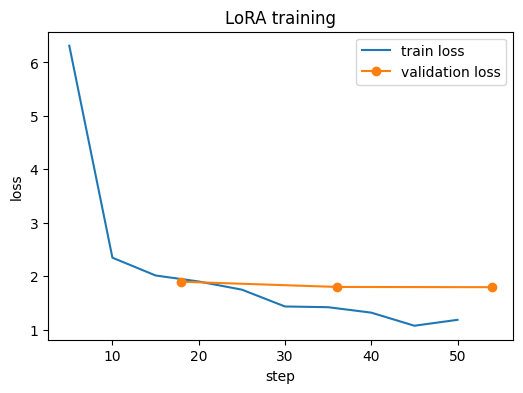

In [12]:
# Loss curve for your report
import matplotlib.pyplot as plt
log = trainer.state.log_history
tr = [(l["step"], l["loss"]) for l in log if "loss" in l]
ev = [(l["step"], l["eval_loss"]) for l in log if "eval_loss" in l]
plt.figure(figsize=(6, 4))
plt.plot(*zip(*tr), label="train loss")
if ev: plt.plot(*zip(*ev), marker="o", label="validation loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("LoRA training")
plt.savefig(os.path.join(RESULTS_DIR, "loss_curve.png"), dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# Save the training log so the web report can draw the loss curve
json.dump(trainer.state.log_history, open(os.path.join(RESULTS_DIR, 'train_log.json'), 'w'))
print('Saved train_log.json. Now copy results/ to your laptop and run: python src/make_report_bundle.py')

Saved train_log.json. Now copy results/ to your laptop and run: python src/make_report_bundle.py


## 6. Fine-tuned model on the same test set

In [14]:
FT_PATH = os.path.join(RESULTS_DIR, "ft_outputs.json")
model.config.use_cache = True
ft_outputs = generate(model, test_prompts)
json.dump(ft_outputs, open(FT_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

for i in range(3):
    print(f"\n[{i+1}] REFERENCE:", test.iloc[i]["target"])
    print("BASE:      ", base_outputs[i])
    print("FINE-TUNED:", ft_outputs[i])

  generated 8/60
  generated 16/60
  generated 24/60
  generated 32/60
  generated 40/60
  generated 48/60
  generated 56/60
  generated 60/60

[1] REFERENCE: these terms apply to www apple com which is owned by apple. if you use this website you agree to the terms if not don t use the site. apple may change the terms at any time and it is your responsibility to check for changes and continued use of the site means you agree with the changes.
BASE:       Here's the legal clause rewritten in simpler language:

The Apple website (www.apple.com and all related sites) belongs to Apple Inc. and its companies. When you visit this website, you agree to follow the rules we've set out. These rules apply to everything on the Apple website, no matter where it is or what it says.

Apple can change these rules anytime they want. They might add new rules, take away old ones, or make other changes. It's important to check these rules
FINE-TUNED: the service can delete your account without prior notic

## 7. Evaluation: base vs fine-tuned (uses src/evaluate.py)

In [15]:
refs = test["target"].tolist()
rows = [
    evaluate.evaluate_model("Base Qwen2.5-3B-Instruct", base_outputs, refs),
    evaluate.evaluate_model("Fine-tuned (LoRA)", ft_outputs, refs),
]
table = evaluate.build_comparison(rows)
evaluate.save_metrics(table)
evaluate.save_examples(test["clause"].tolist(), refs, base_outputs, ft_outputs, n=8)
table

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

... (3 outputs left out)

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Saved metrics -> /content/drive/MyDrive/legal-text-simplification-lora/results/metrics.csv
Saved examples -> /content/drive/MyDrive/legal-text-simplification-lora/results/examples.md


,model,ROUGE-1,ROUGE-2,ROUGE-L,BERTScore-F1,Flesch,Avg words
0,Base Qwen2.5-3B-Instruct,0.1884,0.0337,0.1286,0.8553,62.24,55.3
1,Fine-tuned (LoRA),0.3896,0.2136,0.3494,0.9023,60.27,12.1


## 8. Error analysis: where does the fine-tuned model do worst?

In [16]:
from rouge_score import rouge_scorer
sc = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
df = test.copy()
df["base"], df["ft"] = base_outputs, ft_outputs
df["ft_rougeL"] = [sc.score(r, p)["rougeL"].fmeasure for r, p in zip(df["target"], df["ft"])]
df["base_rougeL"] = [sc.score(r, p)["rougeL"].fmeasure for r, p in zip(df["target"], df["base"])]
print("Fine-tuned better than base on", int((df["ft_rougeL"] > df["base_rougeL"]).sum()), "of", len(df), "test clauses")

for _, r in df.sort_values("ft_rougeL").head(5).iterrows():
    print("\n" + "-" * 60)
    print("CLAUSE:", r["clause"][:300])
    print("REFERENCE:", r["target"])
    print("FINE-TUNED:", r["ft"], f"(ROUGE-L {r['ft_rougeL']:.2f})")
    print("BASE:", r["base"], f"(ROUGE-L {r['base_rougeL']:.2f})")

Fine-tuned better than base on 48 of 60 test clauses

------------------------------------------------------------
CLAUSE: if you wish to cancel your account or request that we no longer use your information to provide you with our services or request that we no longer maintain your information please contact us at info reputation com.
REFERENCE: reputation com service cannot be canceled online but via email with a guaranteed response time.
FINE-TUNED: you can delete your account and request deletion of your personal data. (ROUGE-L 0.00)
BASE: If you want to cancel your account or ask us not to use your information to provide you with our services or to stop keeping your information, you can send an email to info@reputation.com. (ROUGE-L 0.08)

------------------------------------------------------------
CLAUSE: 12. ability to accept terms of serviceyou affirm that you are either more than 18 years of age or an emancipated minor or possess legal parental or guardian consent and are ful

## Optional: reload a saved adapter after a Colab disconnect
Run sections 0 to 3 (this reloads the base model), skip section 5, run this cell, then continue from section 6.

In [17]:
!ls /content/drive/MyDrive/legal-text-simplification-lora/adapter

adapter_config.json	   chat_template.jinja	tokenizer_config.json
adapter_model.safetensors  README.md		tokenizer.json


In [18]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q -U transformers peft accelerate bitsandbytes gradio

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
!python /content/drive/MyDrive/legal-text-simplification-lora/app/app.py

Loading model ...
Loading weights: 100% 434/434 [00:30<00:00, 14.13it/s]
Ready.
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://fb6ca23453d4aae253.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Created dataset file at: .gradio/flagged/dataset1.csv
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3959, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/drive/MyDrive/legal-text-simplification-lora/app/app.py", line 84, in <module>
    demo.launch(share=True)     # share=True gives a public li

In [ ]:
# from peft import PeftModel
# model = PeftModel.from_pretrained(model, ADAPTER_DIR)